# 03｜深度學習：單層 RNN 家族
| Run | Architecture |
|---|---|
| DL-01 | Embedding(100) → SimpleRNN(64) → Dense(1,sigmoid) |
| DL-02 | Embedding(100) → LSTM(64) → Dense(1,sigmoid) |
| DL-03 | Embedding(100) → GRU(64) → Dense(1,sigmoid) |

共用 12,000 詞彙、160 tokens、Adam(0.001)、BCE、batch=128、最多 10 epochs，無 Dropout 與 Early Stopping。固定 seed=42；只使用 Validation，不接觸官方 Test。


In [1]:
from pathlib import Path
import json,sys
ROOT=Path('/workspace/imdb_matrix_experiment/variants/dedup_v1_1')
assert ROOT.is_dir()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display,Image
from src.evaluation import phase1_settings
settings,phase1_hash,manifest=phase1_settings()
print('Variant:',manifest['version'])
print('Split SHA256:',manifest['split_assignments_sha256'])
print('Phase1 SHA256:',phase1_hash)
assert settings['test_policy']=='do_not_evaluate_in_phase1'
import tensorflow as tf
print('TensorFlow',tf.__version__,'GPU',tf.config.list_physical_devices('GPU'))
assert tf.config.list_physical_devices('GPU')
print('Training configuration',settings['deep_learning'])


Variant: dedup_v1.1
Split SHA256: 9e25b0d714d1fb555c8c8a58fa6858c392ec60ecfba554b923553626154174e9
Phase1 SHA256: 5b3e976e16d73ab101abd41f9d022a13d319d221760625f3c6586d1db8d64d29


TensorFlow 2.20.0 GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training configuration {'rnn_types': ['SimpleRNN', 'LSTM', 'GRU'], 'embedding_dim': 100, 'hidden_units': 64, 'batch_size': 128, 'epochs': 10, 'learning_rate': 0.001, 'optimizer': 'Adam', 'loss': 'binary_crossentropy', 'output': 'sigmoid', 'dropout': 0.0, 'early_stopping': False, 'mask_zero': True, 'monitor_val': True, 'primary_threshold': 0.5, 'device': 'GPU0_inside_container', 'train_shuffle': True}


## 1. 共用 Token IDs 與相同資料分割
資料由 Phase 0 v1.1 的 Train-only TextVectorization 產生。

In [2]:
with np.load(ROOT/'artifacts/vectorizers/keras_token_ids_12000_160.npz',allow_pickle=False) as data:
    for split,rows in (('train',19823),('validation',4956)):
        assert data['X_'+split].shape==(rows,160)
        print(split,data['X_'+split].shape,data['y_'+split].shape)


train (19823, 160) (19823,)
validation (4956, 160) (4956,)


## 2. 模型工廠與參數量
三組只改變循環層；hidden units 相等，總參數量不必然相等。

In [3]:
from src.model_factory import make_single_layer_rnn,BASELINES
for run_id in BASELINES:
    tf.keras.utils.set_random_seed(42)
    model=make_single_layer_rnn(run_id)
    print(run_id,BASELINES[run_id],model.count_params(),
          [x.__class__.__name__ for x in model.layers])
    del model
    tf.keras.backend.clear_session()


I0000 00:00:1793792182.923798   10898 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4599 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:02:00.0, compute capability: 7.5


DL-01 SimpleRNN 1210625 ['InputLayer', 'Embedding', 'SimpleRNN', 'Dense']
DL-02 LSTM 1242305 ['InputLayer', 'Embedding', 'LSTM', 'Dense']
DL-03 GRU 1231937 ['InputLayer', 'Embedding', 'GRU', 'Dense']


## 3. GPU 上實際訓練 DL-01、DL-02、DL-03
三組相同預設訓練條件：10 epochs、無 dropout、無 early stopping。
正式執行的模型、loss 曲線、Validation 預測結果會保存到獨立 v1.1 專案。
已有完成且保存的 Run 則不重訓。


In [4]:
import subprocess
wanted=['DL-01-s42','DL-02-s42','DL-03-s42']
registry=ROOT/'results/runs.csv'
existing=set(pd.read_csv(registry).run_id) if registry.exists() else set()
missing=[name[:-4] for name in wanted if name not in existing]
print('Missing full-data models:',missing)
if missing:
    subprocess.run([sys.executable,'-B','-m','src.phase1_rnn','--runs',*missing],cwd=ROOT,check=True)
print('Three RNN family baselines completed.')


Missing full-data models: []
Three RNN family baselines completed.


## 4. Validation 分數及訓練成本
Accuracy、Precision、Recall、F1、最後 epoch 的 Validation Loss、參數量、訓練時間及推論時間。

In [5]:
rows=pd.read_csv(ROOT/'results/runs.csv')
selected=rows[rows.run_id.isin(wanted)].sort_values('run_id')
assert len(selected)==3 and selected.run_id.is_unique
display(selected[['run_id','model_name','val_accuracy','val_precision','val_recall','val_f1',
                  'val_loss','trainable_params','epochs_completed',
                  'train_time_sec','inference_time_sec']].round(4))


,run_id,model_name,val_accuracy,val_precision,val_recall,val_f1,val_loss,trainable_params,epochs_completed,train_time_sec,inference_time_sec
1,DL-01-s42,SimpleRNN,0.7050,0.6977,0.7280,0.7125,1.1702,1210625.0,10.0,18.8431,0.4337
2,DL-02-s42,LSTM,0.8247,0.8525,0.7871,0.8185,0.7924,1242305.0,10.0,13.6681,0.1738
3,DL-03-s42,GRU,0.8099,0.8125,0.8080,0.8102,0.7745,1231937.0,10.0,12.2460,0.1640


## 5. Loss 曲線與混淆矩陣
10 epoch 曲線允許觀察過度擬合；此基準不使用 EarlyStopping。

DL-01-s42


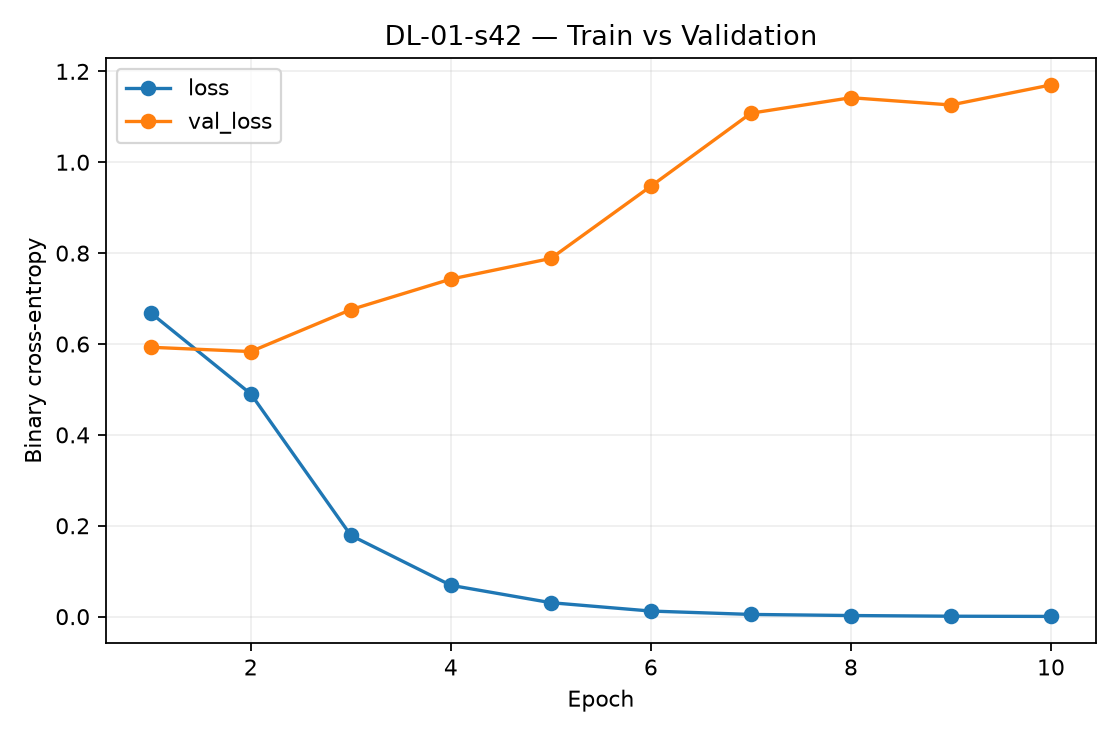

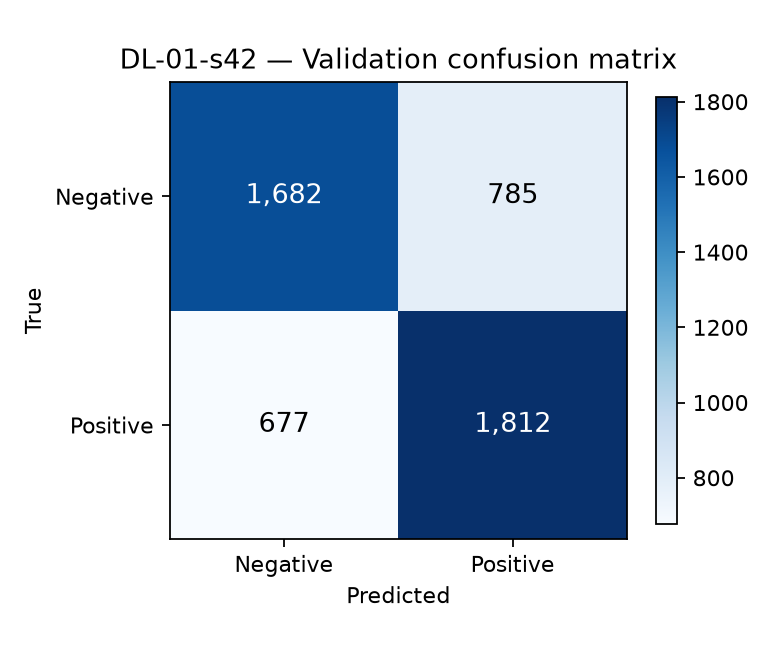

DL-02-s42


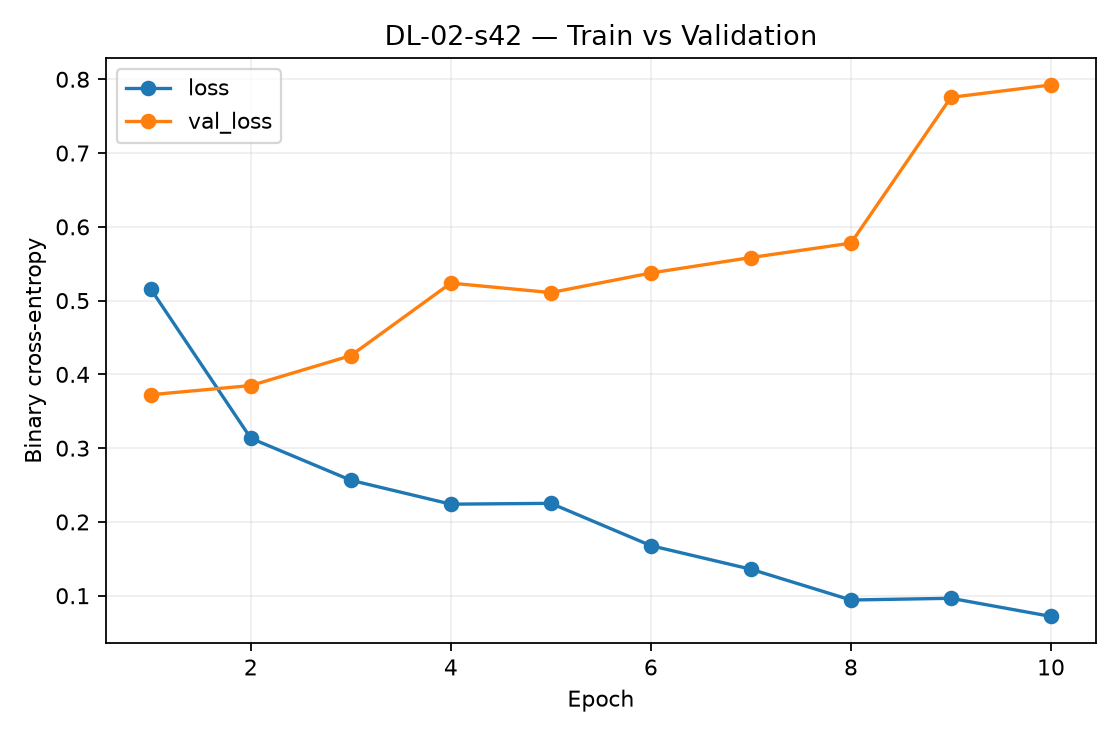

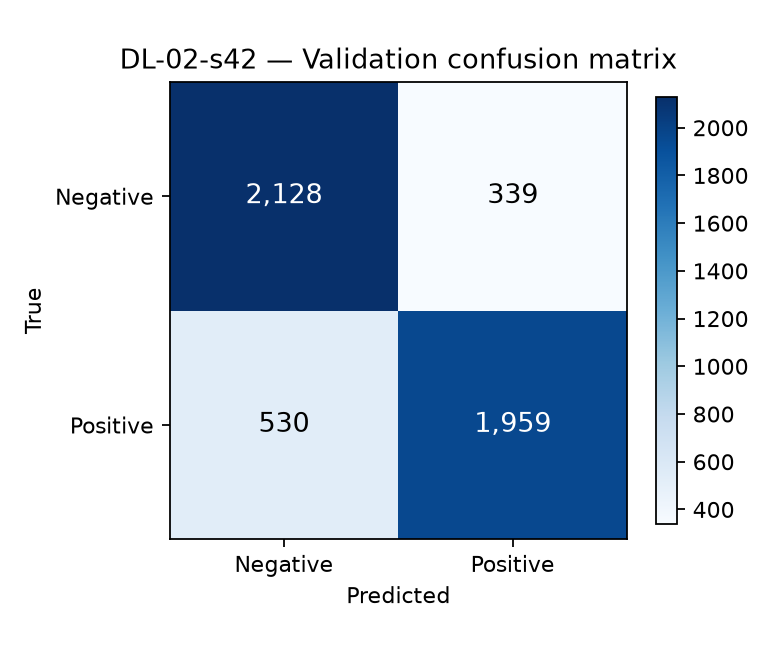

DL-03-s42


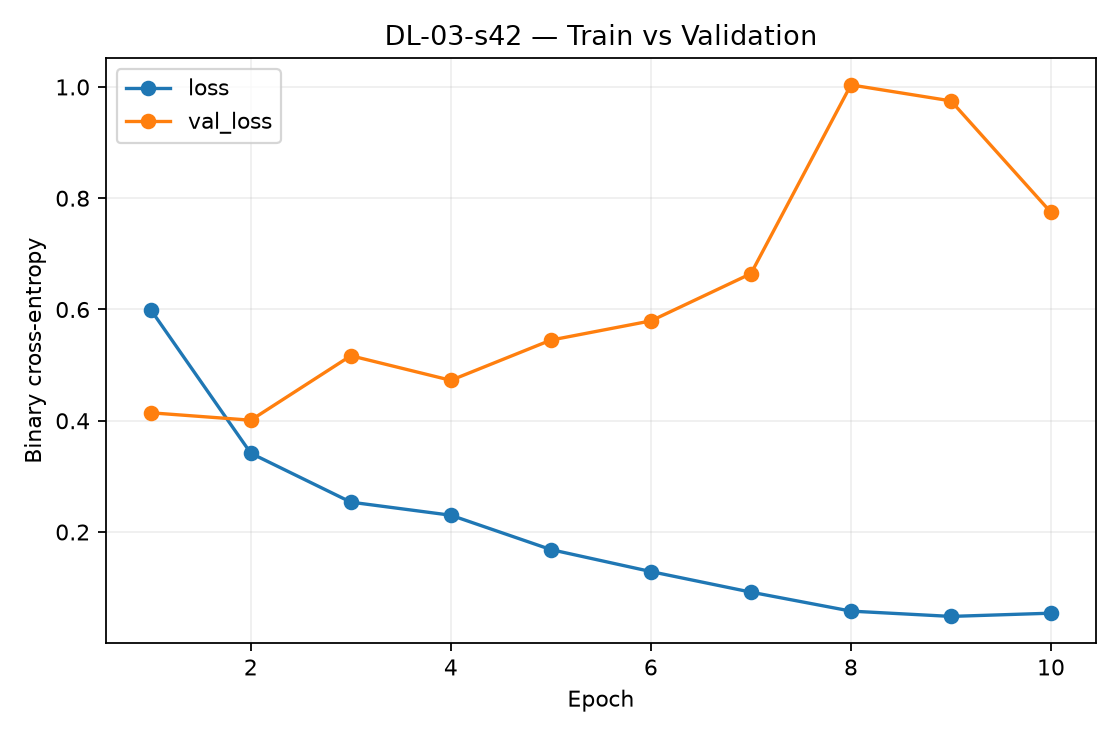

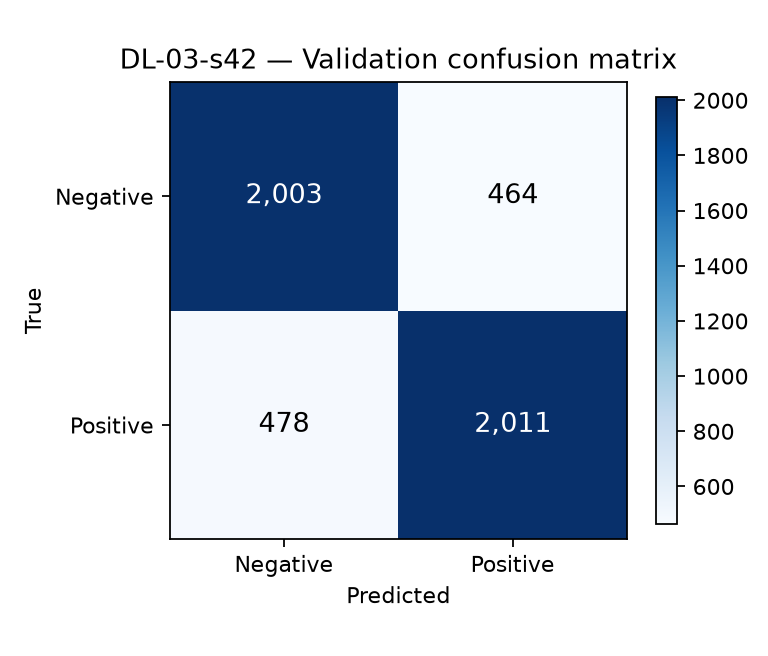

In [6]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,3.8))
ax.bar(selected.run_id,selected.val_f1)
ax.set(ylim=(0,1),ylabel='Validation F1',title='Single-layer RNN — dedup_v1.1')
ax.grid(axis='y',alpha=.2)
plt.show()
for rid in selected.run_id:
    print(rid)
    display(Image(filename=str(ROOT/('results/figures/'+rid+'_learning_curve.png')),width=540))
    display(Image(filename=str(ROOT/('results/figures/'+rid+'_val_confusion_matrix.png')),width=360))


## Phase 1 DL 結果
DL-02 是 Phase 2 LSTM Dropout×EarlyStopping 比較中不重訓的基準。
單次 seed 的高低不是統計顯著性結論；後續依 Validation 而非 Test 選模型。